# Part A: Conceptual Understanding (Theory)

## 1. What are Supervised Learning Algorithms?

- Supervised learning is a type of machine learning in which a model learns from a labeled dataset containing input features and their corresponding output values.
- The model identifies patterns and relationships between inputs and outputs to make predictions on new, unseen data.
---

## 2. Difference Between Regression Algorithms and Classification Algorithms


| Basis | Regression | Classification |
| :--- | :--- | :--- |
| **Purpose** | Predicts continuous numerical values | Predicts categories or classes |
| **Output** | A number | A class label |
| **Example** | Predicting house prices | Predicting whether a house is expensive or affordable |
| **Algorithms** | Linear Regression, Polynomial Regression, Random Forest Regressor | Logistic Regression, Decision Tree Classifier, Random Forest Classifier |
| **Evaluation metrics** | MAE, MSE, RMSE, R² | Accuracy, Precision, Recall, F1-score |
---

## 3. Explain Simple Linear Regression

Simple Linear Regression is a supervised machine learning algorithm that models the relationship between one independent variable and one dependent variable using a straight line.

The equation is:- y = mx + c

(y) = Predicted dependent variable

(x) = Independent variable

(m) = Slope of the regression line

(c) = Intercept of the regression line

---

## 4. List and Explain the Assumptions of Linear Regression

1. Linearity
2. Independence of Errors
3. Homoscedasticity
4. Normality of Residuals
5. No Perfect Multicollinearity
6. No Influential Outliers
---
1. Linearity:- There should be a linear relationship between the independent variables and the expected value of the dependent variable.
2. Independence of Errors:- The model's residuals (prediction errors) should be independent of one another.

3. Homoscedasticity:- The variance of the residuals should remain approximately constant across different fitted values.

4. Normality of Residuals:- For conventional statistical inference, such as confidence intervals and hypothesis tests, residuals should be approximately normally distributed.

5. No Perfect Multicollinearity:- In multiple linear regression, independent variables should not have perfect linear relationships with one another.

6. No Influential Outliers:- Extreme observations should not unduly influence the fitted regression model.
---


## 5. What Is the Bias–Variance Trade-Off?

Bias:- Bias is the error caused by overly simple assumptions in a model. A model with high bias may fail to capture important patterns in the data, resulting in underfitting.

Variance:- Variance measures how much a model's predictions change when it is trained on different datasets. A model with high variance may learn noise in the training data, resulting in overfitting.

---

## 6. Explain Overfitting and Underfitting with Examples

1. Overfitting:- Overfitting occurs when a model learns the training data too closely, including random noise and unusual patterns. As a result, it performs very well on training data but poorly on unseen data.

- Example:- A high-degree polynomial regression model may pass close to almost every training observation but make inaccurate predictions for new house prices.



2. Underfitting:- Underfitting occurs when a model is too simple to capture the underlying patterns in the data. It performs poorly on both training and testing data.

- Example: A simple linear model may fail to represent a genuinely nonlinear relationship between house area and price.
---

# Part B: Dataset Understanding & Preparation

## 7. Identify Independent and Dependent Variables

### import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

 ### Load the dataset

In [ ]:
df = pd.read_csv("/content/RealEstate_HousePrice_Dataset_4200 - RealEstate_HousePrice_Dataset_4200.csv.csv")

### Display the first five rows

In [ ]:
display(df.head())

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


### Check the number of rows and columns

In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (4200, 12)


### Display column **names**

In [ ]:
print(df.columns.tolist())

['house_id', 'area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago', 'house_price_inr']


### Check data types

In [ ]:
print(df.dtypes)

house_id                  int64
area_sqft                 int64
bedrooms                  int64
bathrooms                 int64
location_score          float64
age_years                 int64
distance_city_km        float64
lot_size_sqft             int64
has_garage                int64
has_pool                  int64
renovation_years_ago      int64
house_price_inr           int64
dtype: object


###  Check missing values

In [ ]:
print(df.isnull().sum())

house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64


### Check duplicate rows

In [ ]:
print(df.duplicated().sum())

0


### Define the target variable

In [ ]:
y = df["house_price_inr"]

### Define the independent variables

In [ ]:
X = df.drop(columns=["house_id", "house_price_inr"])

### Display the independent variables

In [ ]:
print(X.columns.tolist())

['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']


### Display the dependent variable

In [ ]:
print(y.name)

house_price_inr


### Check their dimensions

In [ ]:
print("\nX shape:", X.shape)
print("y shape:", y.shape)


X shape: (4200, 10)
y shape: (4200,)


## 8. Visualize Relationships Between Features and the Target Variable

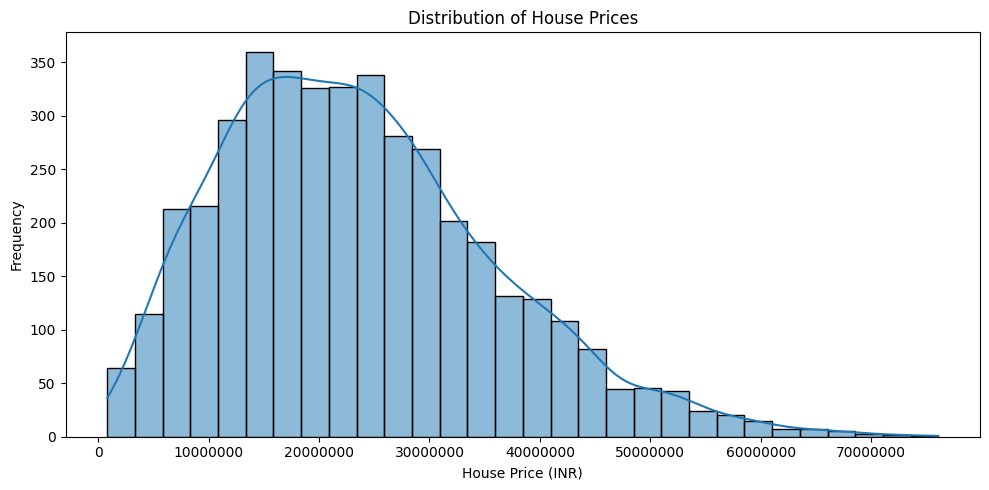

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="house_price_inr",
    bins=30,
    kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price (INR)")
plt.ylabel("Frequency")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

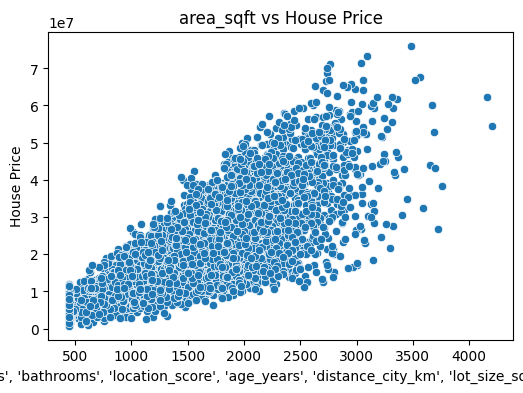

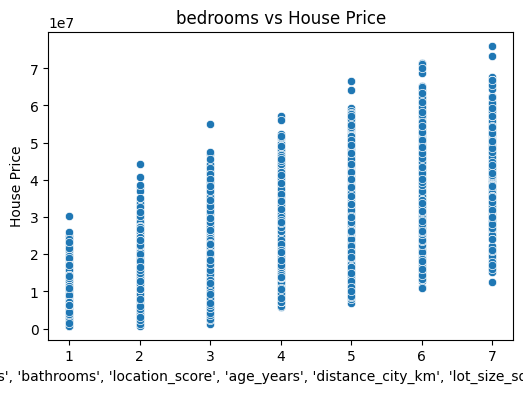

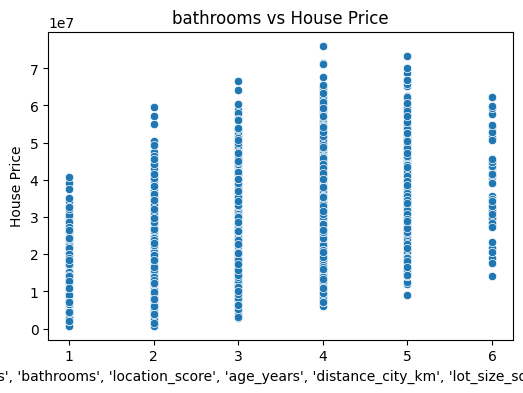

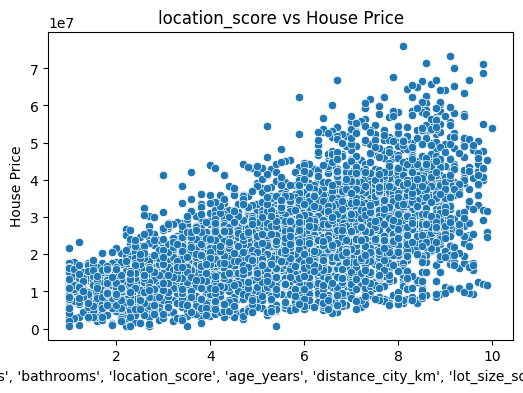

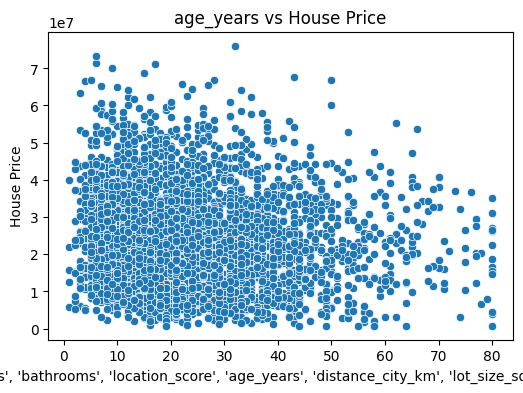

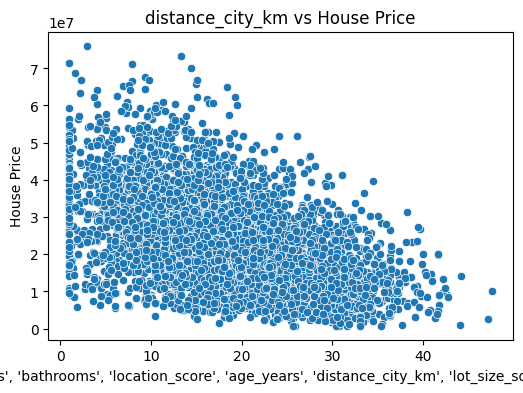

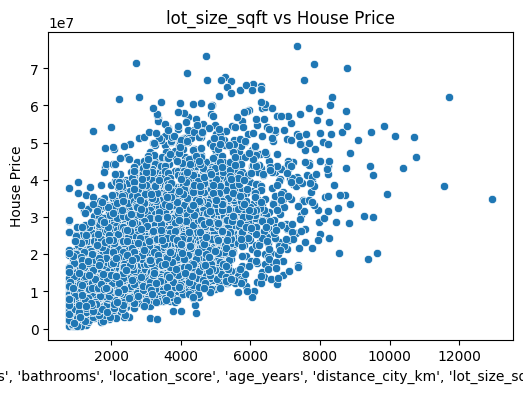

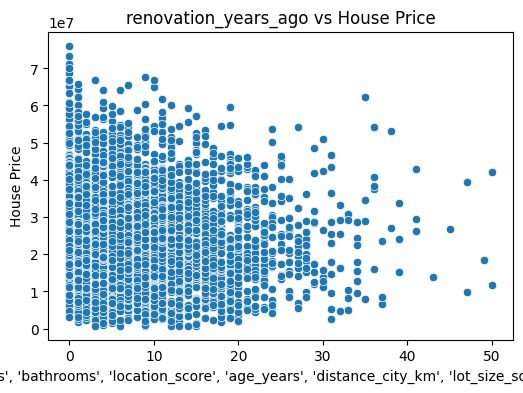

In [ ]:
details = [
    "area_sqft", "bedrooms",
    "bathrooms", "location_score",
    "age_years", "distance_city_km",
    "lot_size_sqft", "renovation_years_ago"]

for detail in details:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[detail], y=df["house_price_inr"])
    plt.title(detail + " vs House Price")
    plt.xlabel(details)
    plt.ylabel("House Price")
    plt.show()

### 9. Split the Dataset into Training and Testing Sets

### Define dependent variable

In [ ]:
y = df["house_price_inr"]

### Define independent variables

In [ ]:
X = df.drop(["house_id", "house_price_inr"],axis=1)

### Split the dataset into training and testing sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

### Display the shapes of the datasets

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3360, 10)
X_test shape: (840, 10)
y_train shape: (3360,)
y_test shape: (840,)


# Part C: Simple Linear Regression

## 10. Implement Simple Linear Regression

### Select one independent feature

In [ ]:
X_simple_train = X_train[["area_sqft"]]
X_simple_test = X_test[["area_sqft"]]

### Create the Simple Linear Regression model

In [ ]:
simple_model = LinearRegression()

### Train the model

In [ ]:
simple_model.fit(X_simple_train, y_train)

LinearRegression()

### Predict house prices on the test dataset

In [ ]:
y_pred_simple = simple_model.predict(X_simple_test)

### Display model coefficients

In [ ]:
print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Slope: 14788.306111307542
Intercept: -1163519.1764186136


### Display sample actual and predicted prices

In [ ]:
results = pd.DataFrame({"Actual Price": y_test.values,"Predicted Price": y_pred_simple})

In [ ]:
display(results.head(10))

,Actual Price,Predicted Price
0,36890986,3.440236e+07
1,27836840,2.733355e+07
2,15321534,2.677159e+07
3,30812774,2.180272e+07
4,18194835,3.104541e+07
5,32960272,2.428716e+07
6,10714707,1.860845e+07
7,44555593,3.741917e+07
8,21525184,2.724482e+07
9,42840000,2.804339e+07


### Predict the price of a 2000 sq.ft house


In [ ]:
new_house = pd.DataFrame({"area_sqft": [5600]})

In [ ]:
predicted_price = simple_model.predict(new_house)

In [ ]:
print("House Area:", 2000, "sq.ft")
print("Predicted House Price: ₹", round(predicted_price[0], 2))

House Area: 2000 sq.ft
Predicted House Price: ₹ 81650995.05


## 11. Plot the Regression Line and Interpret Slope & Intercept

### Create values for the regression line

In [ ]:
x_line = np.linspace(X_train["area_sqft"].min(),X_train["area_sqft"].max(),100)


### Predict prices for the regression line

In [ ]:
y_line = simple_model.predict(pd.DataFrame({"area_sqft": x_line}))

### Plot actual data and regression line

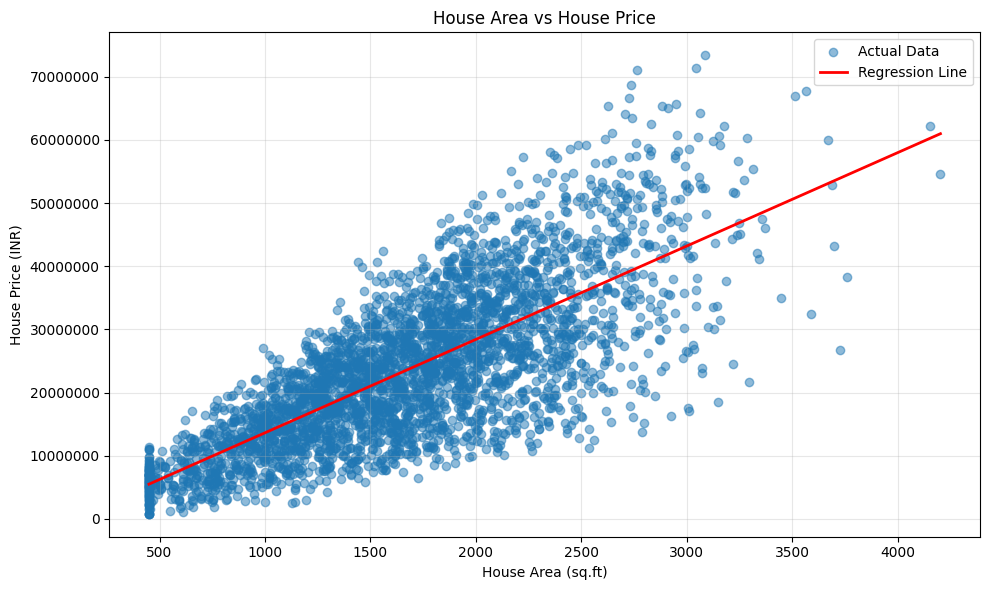

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_train["area_sqft"],
    y_train,
    alpha=0.5,
    label="Actual Data")
plt.plot(
    x_line,
    y_line,
    color="red",
    linewidth=2,
    label="Regression Line")
plt.title("House Area vs House Price")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
slope = simple_model.coef_[0]
print("Slope:", slope)

Slope: 14788.306111307542


In [ ]:
intercept = simple_model.intercept_
print("Intercept:", intercept)

Intercept: -1163519.1764186136


## 12: Validate Linear Regression Assumptions

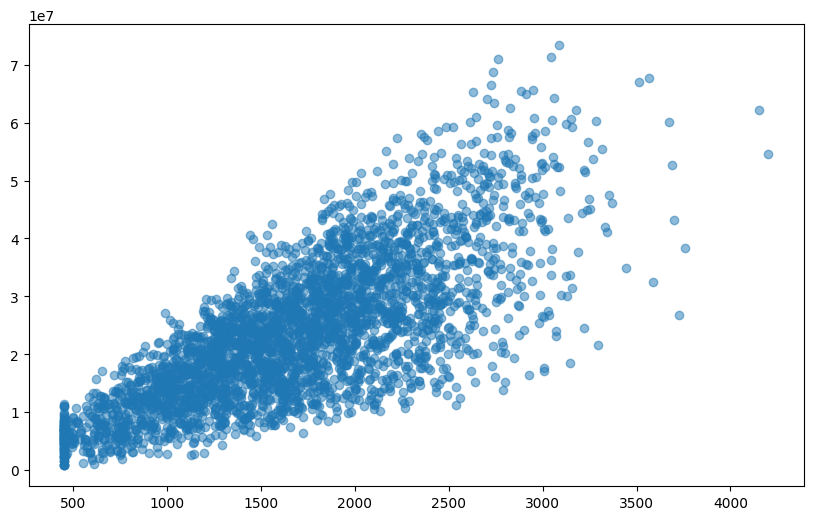

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_train["area_sqft"],
    y_train,
    alpha=0.5,
    label="Actual Data")

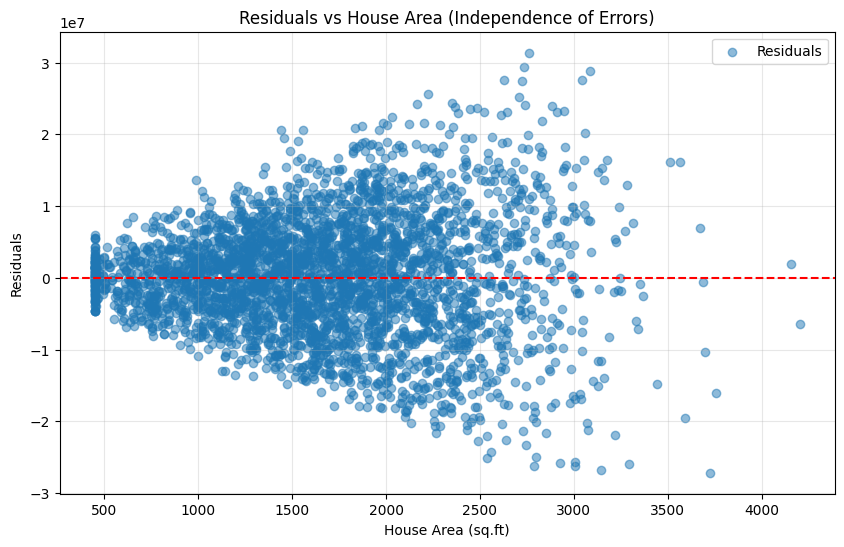

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    X_train["area_sqft"],
    y_train - simple_model.predict(X_train[["area_sqft"]]),
    alpha=0.5,
    label="Residuals")
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residuals vs House Area (Independence of Errors)")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("Residuals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

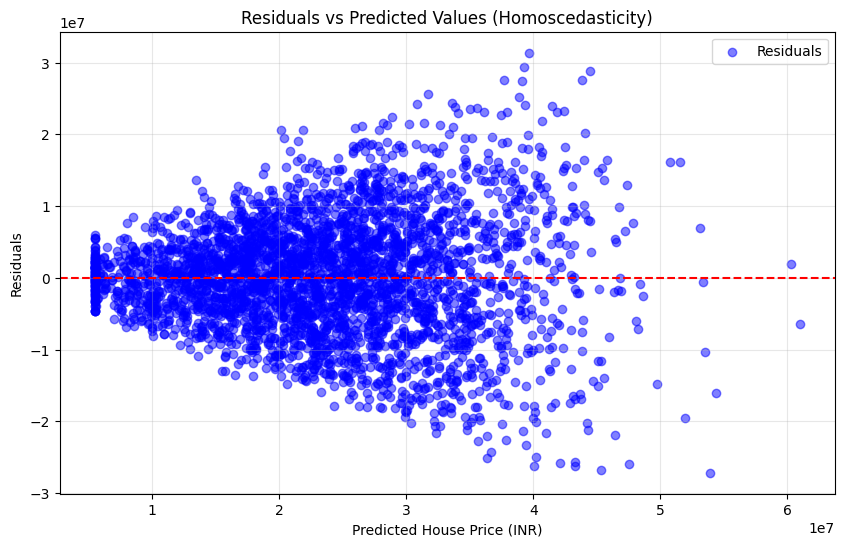

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    simple_model.predict(X_train[["area_sqft"]]),
    y_train - simple_model.predict(X_train[["area_sqft"]]),
    alpha=0.5,
    color="blue",
    label="Residuals")
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residuals vs Predicted Values (Homoscedasticity)")
plt.xlabel("Predicted House Price (INR)")
plt.ylabel("Residuals")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# D — Model Evaluation Metrics

## 13. Calculate regression evaluation metrics

### Calculate MSE

In [ ]:
mse = mean_squared_error(y_test, y_pred_simple)
print(mse)

66989260021849.47


### Calculate MAE

In [ ]:
mae = mean_absolute_error(y_test, y_pred_simple)
print(mae)

6294593.696131912




### Calculate RMSE

In [ ]:
rmse = np.sqrt(mse)
print(rmse)

8184696.696997969


### Calculate R²

In [ ]:
r2 = r2_score(y_test, y_pred_simple)
print(r2)

0.5625199587991578


### Calculate Adjusted R²

In [ ]:
n = len(y_test)
p = 1
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print(adjusted_r2)

0.5619979062440257


## 14. Interpretation of Model Evaluation Metrics

1. MSE:-
   - Measures the average squared prediction error.
   - Lower MSE indicates better predictions.
   - Unit: INR².

3. RMSE:-
   - Square root of MSE.
   - Measures prediction error and penalizes large errors.
   - Lower RMSE indicates better performance.
   - Unit: INR.

4. R² Score:-
   - Measures how much variation in house prices the model explains.
   - Closer to 1 generally indicates a better fit.
   - A negative score indicates performance worse than the test-set mean baseline.

5. Adjusted R² Score:-
   - Adjusts R² based on the number of independent variables.
   - Penalizes unnecessary model complexity.
   - Useful for comparing regression models with different numbers of features.

# E — Multiple Linear Regression

## 15. Implement Multiple Linear Regression

### Create the model

In [ ]:
multiple_model = LinearRegression()

### Train the model

In [ ]:
multiple_model.fit(X_train, y_train)

LinearRegression()

### Predict house prices

In [ ]:
y_pred_multiple = multiple_model.predict(X_test)

In [ ]:
print(multiple_model.intercept_)

-14766762.745674696


In [ ]:
for feature, coefficient in zip(X_train.columns, multiple_model.coef_):
    print(f"{feature}: {coefficient:.2f}")

area_sqft: 13795.94
bedrooms: 197643.11
bathrooms: 185944.54
location_score: 3073173.50
age_years: -65609.24
distance_city_km: -98965.16
lot_size_sqft: 103.51
has_garage: 93924.36
has_pool: 455290.23
renovation_years_ago: -21435.91


### MSE

In [ ]:
mse_multiple = mean_squared_error(y_test, y_pred_multiple)
print(mse_multiple)

12592918884127.615


### MAE

In [ ]:
mae_multiple = mean_absolute_error(y_test, y_pred_multiple)
print(mae_multiple)

2604991.4061556906


### RMSE

In [ ]:
rmse_multiple = np.sqrt(mse_multiple)
print(rmse_multiple)

3548650.290480539


### R2

In [ ]:
r2_multiple = r2_score(y_test, y_pred_multiple)
print(r2_multiple)

0.9177606877509898


## 16. Compare Multiple Linear Regression with Simple Linear Regression

In [ ]:
compare = pd.DataFrame({"Model":["Simple Linear Regression","Multiple Linear Regression"],"MSE":[mse,mse_multiple],"MAE":[mae,mae_multiple],"RMSE":[rmse,rmse_multiple],"R2":[r2,r2_multiple]})

In [ ]:
compare

,Model,MSE,MAE,RMSE,R2
0,Simple Linear Regression,6.698926e+13,6.294594e+06,8.184697e+06,0.562520
1,Multiple Linear Regression,1.259292e+13,2.604991e+06,3.548650e+06,0.917761


## 17. Why does performance improve or degrade?

Multiple Linear Regression improves performance when additional features provide useful information about house prices, but performance may degrade due to irrelevant features, multicollinearity, noise, or overfitting.

# PART D - Polynomial Regression

## 18: Implement Polynomial Regression

In [ ]:
X_train_poly = X_train[["area_sqft"]]
X_test_poly = X_test[["area_sqft"]]

In [ ]:
poly = PolynomialFeatures(degree=2)

In [ ]:
X_train_poly_transformed = poly.fit_transform(X_train_poly)
X_test_poly_transformed = poly.transform(X_test_poly)

In [ ]:
poly_model = LinearRegression()
poly_model.fit(X_train_poly_transformed, y_train)

LinearRegression()

In [ ]:
y_pred_poly = poly_model.predict(X_test_poly_transformed)

In [ ]:
print(poly_model.intercept_)
print(poly_model.coef_)

-1932924.643863313
[ 0.00000000e+00  1.58197913e+04 -2.98716068e-01]


## 20.Identify Overfitting and Underfitting in Polynomial Regression

### Predict on training data

In [ ]:
y_train_poly_pred = poly_model.predict(X_train_poly_transformed)

### Predict on testing data

In [ ]:
y_test_poly_pred = poly_model.predict(X_test_poly_transformed)

### Calculate training R2 and RMSE

In [ ]:
train_r2 = r2_score(y_train, y_train_poly_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_poly_pred))

### Calculate testing R2 and RMSE

In [ ]:
test_r2 = r2_score(y_test, y_test_poly_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_poly_pred))

In [ ]:
print(f"Training R2: {train_r2:.2f}")
print(f"Testing R2: {test_r2:.2f}")
print(f"Training RMSE: {train_rmse:.2f}")
print(f"Testing RMSE: {test_rmse:.2f}")

Training R2: 0.57
Testing R2: 0.56
Training RMSE: 8102912.52
Testing RMSE: 8183089.09


# PART G - Gradient Descent

## 21. Explain Gradient Descent



* Gradient Descent is an optimization algorithm that helps a machine learning model find the best values of coefficients and intercept by minimizing prediction errors.
* It repeatedly updates model parameters in the direction that reduces the loss function.



## 22. Batch Gradient Descent from Scratch

In [ ]:
X_gd = X_train[["area_sqft"]].values
y_gd = y_train.values

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_gd).flatten()

In [ ]:
w = 0.0
b = 0.0

In [ ]:
learning_rate = 0.01
epochs = 1000
n = len(X_scaled)

In [ ]:
loss_history = []

In [ ]:
for epoch in range(epochs):

    y_pred_gd = w * X_scaled + b

    error = y_pred_gd - y_gd

    dw = (2 / n) * np.sum(X_scaled * error)
    db = (2 / n) * np.sum(error)

    w = w - learning_rate * dw
    b = b - learning_rate * db

    loss = np.mean(error ** 2)
    loss_history.append(loss)

In [ ]:
print("Final Weight:", w)
print("Final Bias:", b)
print("Final MSE:", loss_history[-1])

Final Weight: 9374999.572412089
Final Bias: 23517754.36458705
Final MSE: 65681753778600.16


## 23. Stochastic Gradient Descent

In [ ]:
w_sgd = 0.0
b_sgd = 0.0

In [ ]:
learning_rate = 0.001
epochs = 100
n = len(X_scaled)

In [ ]:
sgd_loss_history = []

In [ ]:
for epoch in range(epochs):

    indices = np.random.permutation(n)

    for i in indices:

        x = X_scaled[i]
        y = y_gd[i]

        y_pred = w_sgd * x + b_sgd

        error = y_pred - y

        dw = 2 * x * error
        db = 2 * error

        w_sgd = w_sgd - learning_rate * dw
        b_sgd = b_sgd - learning_rate * db

    predictions = w_sgd * X_scaled + b_sgd
    loss = np.mean((predictions - y_gd) ** 2)

    sgd_loss_history.append(loss)


In [ ]:
print("Final Weight:", w_sgd)
print("Final Bias:", b_sgd)
print("Final MSE:", sgd_loss_history[-1])

Final Weight: 8751741.118326642
Final Bias: 22893082.795521382
Final MSE: 66460419517503.945


1. Project Overview
The Predictive Insight Engine is a Machine Learning regression project designed to predict house prices based on different property features.
---
2. Dataset Description
- Dataset: RealEstate_HousePrice_Dataset_4200.csv
- Total Records: 4,200
- Target Variable: house_price_inr
- Input Features: Area, bedrooms, bathrooms, location score, age, distance from city, lot size, garage, pool, and renovation details.
---
3. Data Preprocessing
- Loaded and inspected the dataset.
- Checked missing values and duplicate records.
- Selected independent and dependent variables.
- Split the dataset into training and testing sets (80:20).
---
4. Exploratory Data Analysis (EDA)
- Created histograms to understand data distributions.
- Used scatter plots to analyze feature relationships with house prices.
- Studied correlations between numerical features.
- Identified important factors affecting house prices.
---
5. Machine Learning Models
Implemented and compared:
  - Simple Linear Regression
  - Multiple Linear Regression
  - Polynomial Regression
  - Batch Gradient Descent
  - Stochastic Gradient Descent
---
6. Model Evaluation
Evaluated model performance using:
- Mean Squared Error (MSE)
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score
- Adjusted R² Score

